# Hands-on clustering exercise on Credit Card Data

## The goal of this excercise is to complete the hands-on experience task with similar task description as the project has.

**Dataset**

Dataset downloaded for download is here https://www.kaggle.com/arjunbhasin2013/ccdata

And also here: https://raw.githubusercontent.com/jplatos/Fundamentals-of-Machine-Learning/refs/heads/main/CCGENERAL.csv

**Context**

This case requires to develop a customer segmentation to define marketing strategy. The sample Dataset summarizes the usage behavior of about 9000 active credit card holders during the last 6 months. The file is at a customer level with 18 behavioral variables.

**Content**

* CUSTID : Identification of Credit Card holder (Categorical)
* BALANCE : Balance amount left in their account to make purchases
* BALANCEFREQUENCY : How frequently the Balance is updated, score between 0 and 1 (1 = frequently updated, 0 = not frequently updated)
* PURCHASES : Amount of purchases made from account
* ONEOFFPURCHASES : Maximum purchase amount done in one-go
* INSTALLMENTSPURCHASES : Amount of purchase done in installment
* CASHADVANCE : Cash in advance given by the user
* PURCHASESFREQUENCY : How frequently the Purchases are being made, score between 0 and 1 (1 = frequently purchased, 0 = not frequently purchased)
* ONEOFFPURCHASESFREQUENCY : How frequently Purchases are happening in one-go (1 = frequently purchased, 0 = not frequently purchased)
* PURCHASESINSTALLMENTSFREQUENCY : How frequently purchases in installments are being done (1 = frequently done, 0 = not frequently done)
* CASHADVANCEFREQUENCY : How frequently the cash in advance being paid
* CASHADVANCETRX : Number of Transactions made with "Cash in Advanced"
* PURCHASESTRX : Numbe of purchase transactions made
* CREDITLIMIT : Limit of Credit Card for user
* PAYMENTS : Amount of Payment done by user
* MINIMUM_PAYMENTS : Minimum amount of payments made by user
* PRCFULLPAYMENT : Percent of full payment paid by user
* TENURE : Tenure of credit card service for user


# Goal of the exercises


1. Load the data from as shown in the link bellow.
2. Made the explorative analysis on the data.
3. Evaluate the missing values, scale of the data.
4. Apply k-means or aglomerative clustering and chose the propriate number of clusters.
5. Describe the clusters and their difference.





In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

Tvar dat: (8950, 18)

Prvních 5 řádků:


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12



Názvy sloupců:
['CUST_ID', 'BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8949.000000,8950.000000,8637.000000,8950.000000,8950.000000
mean,1564.474828,0.877271,1003.204834,592.437371,411.067645,978.871112,0.490351,0.202458,0.364437,0.135144,3.248827,14.709832,4494.449450,1733.143852,864.206542,0.153715,11.517318
std,2081.531879,0.236904,2136.634782,1659.887917,904.338115,2097.163877,0.401371,0.298336,0.397448,0.200121,6.824647,24.857649,3638.815725,2895.063757,2372.446607,0.292499,1.338331
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.019163,0.000000,6.000000
25%,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,1600.000000,383.276166,169.123707,0.000000,12.000000
50%,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,3000.000000,856.901546,312.343947,0.000000,12.000000
75%,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,4.000000,17.000000,6500.000000,1901.134317,825.485459,0.142857,12.000000
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,47137.211760,1.000000,1.000000,1.000000,1.500000,123.000000,358.000000,30000.000000,50721.483360,76406.207520,1.000000,12.000000


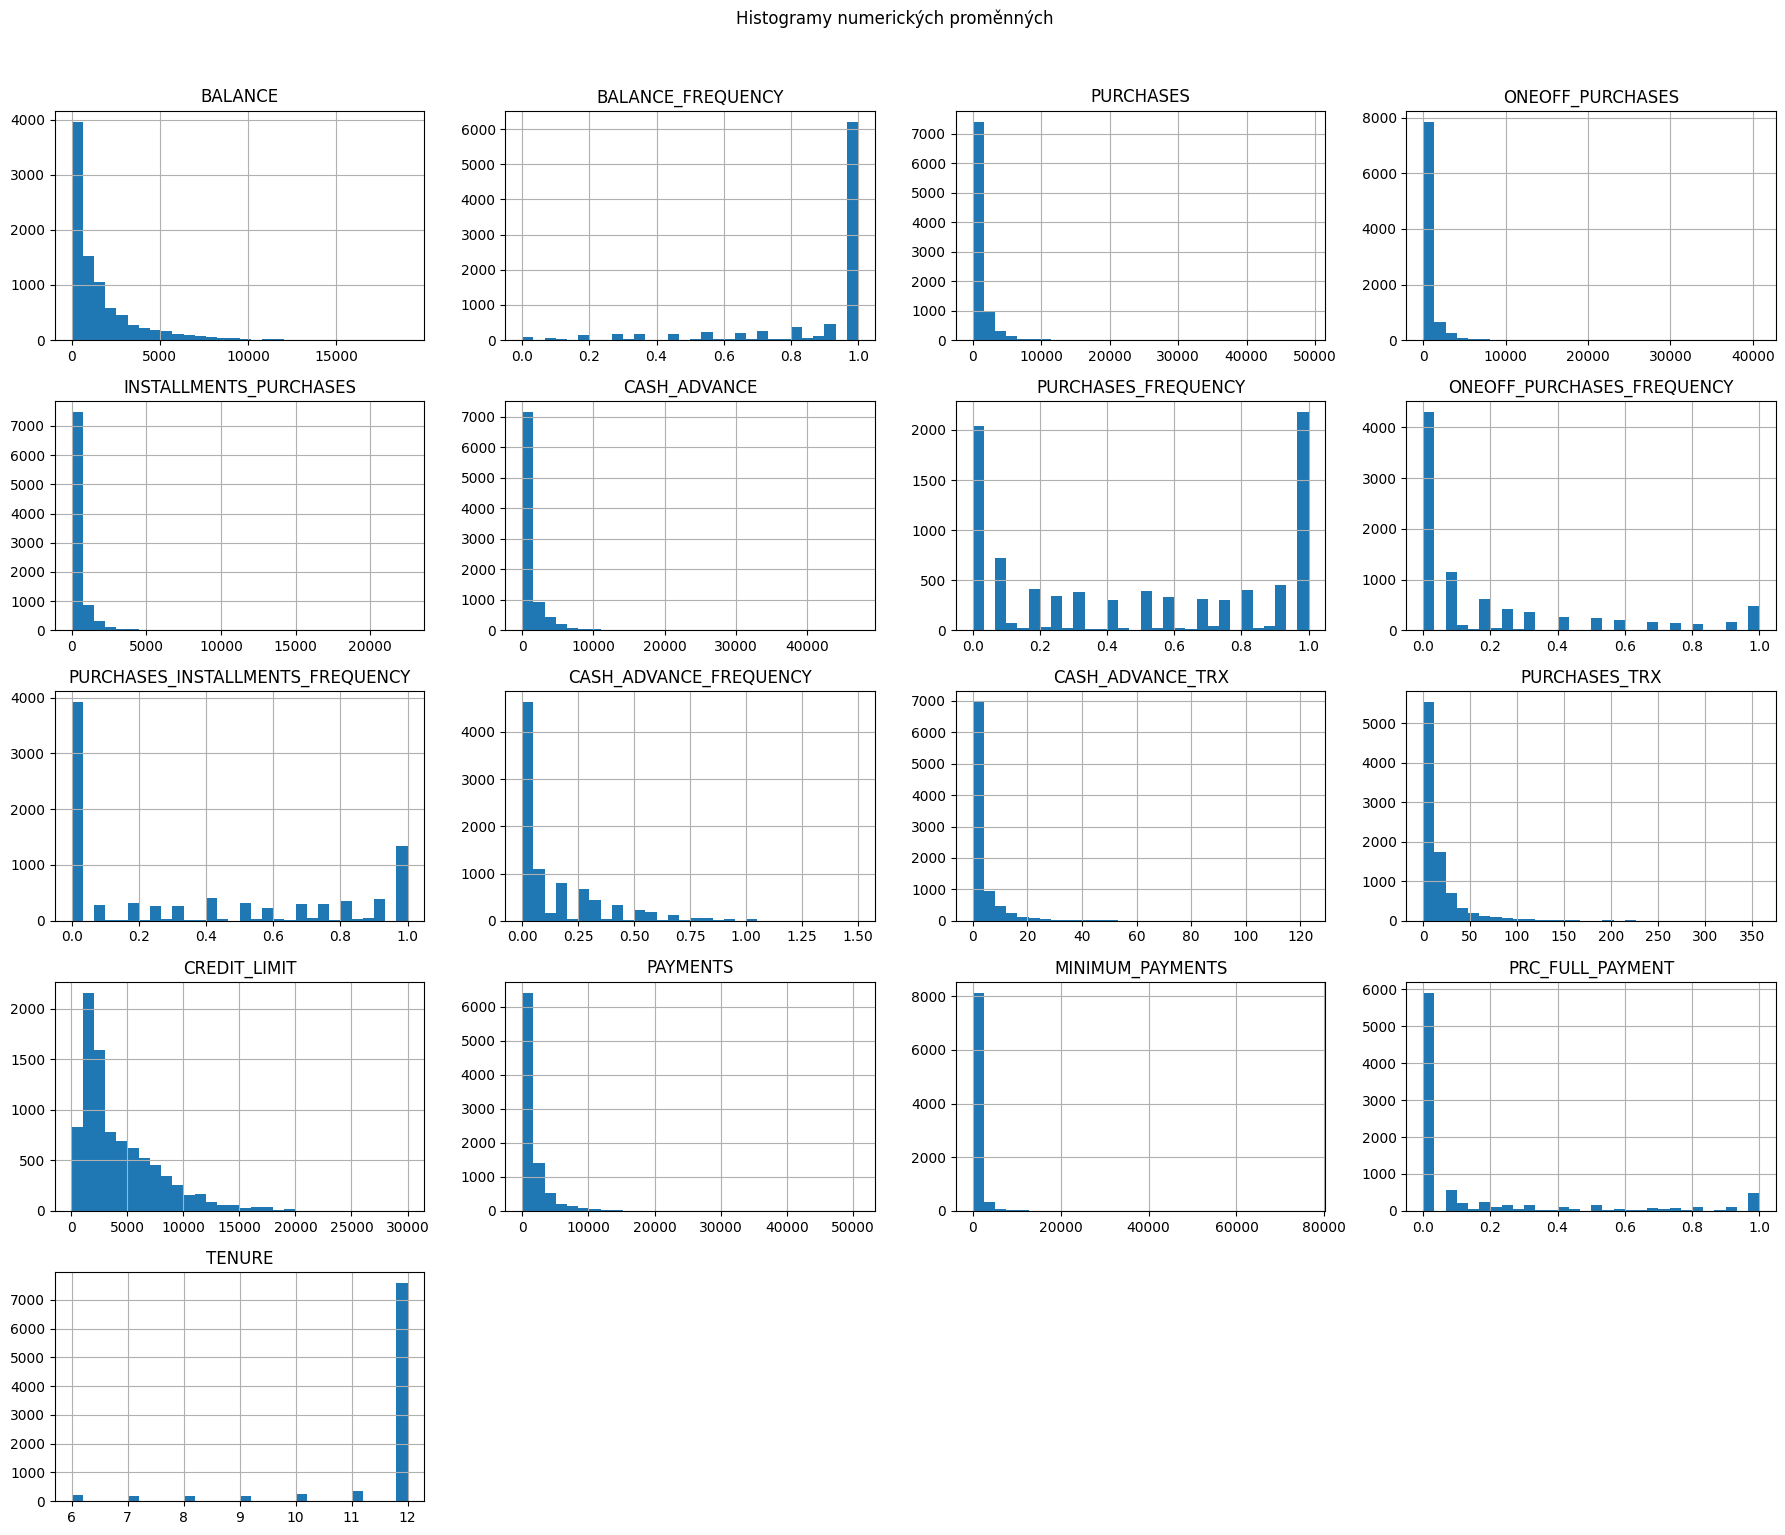

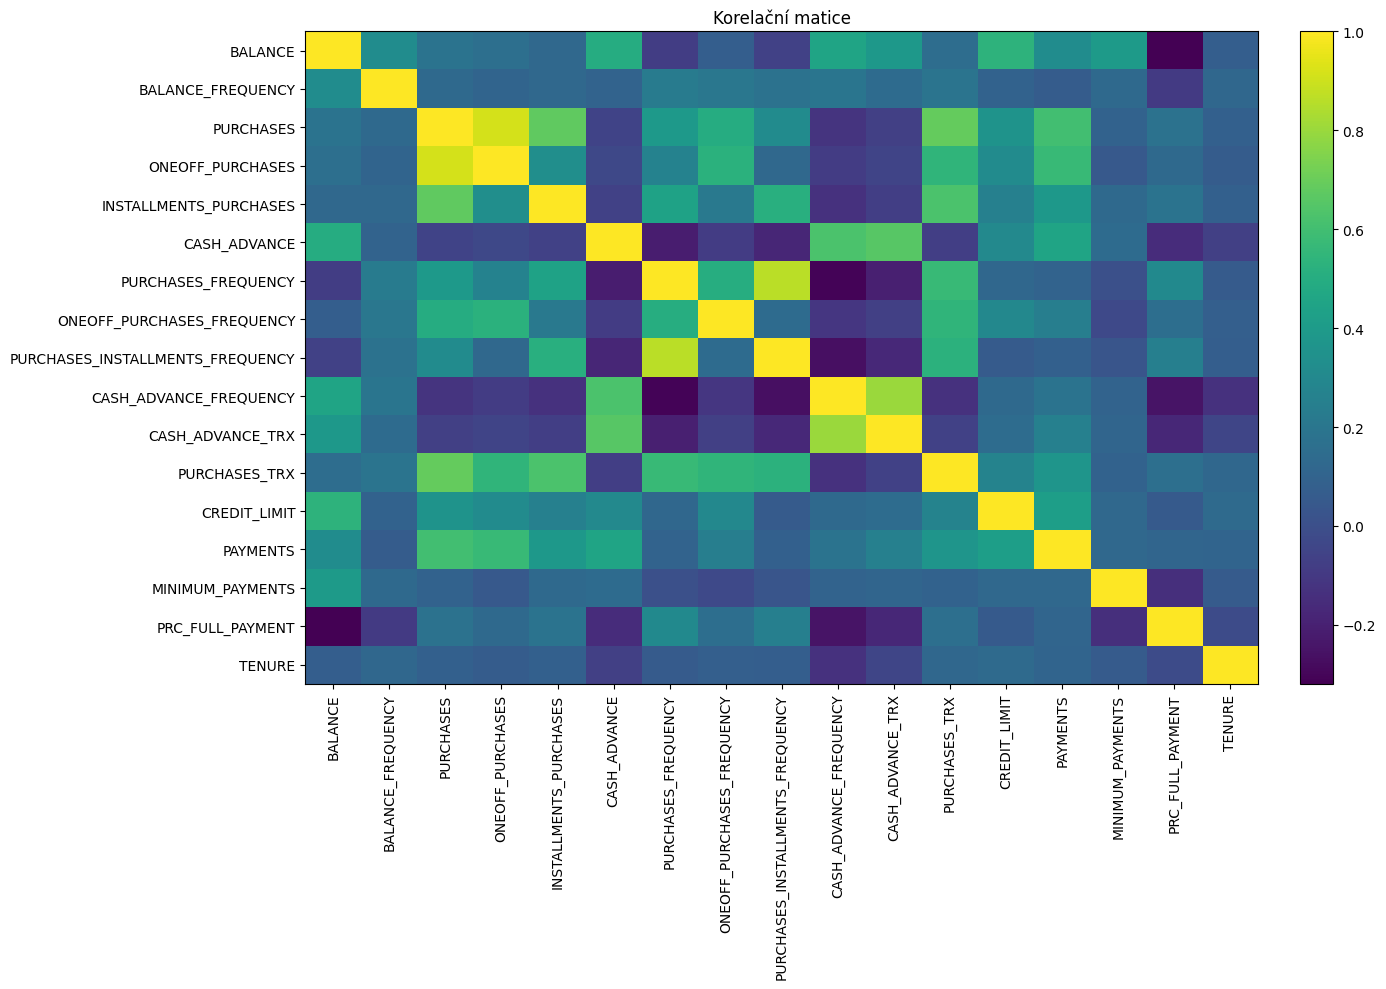


Chybějící hodnoty na sloupec:


MINIMUM_PAYMENTS    313
CREDIT_LIMIT          1
dtype: int64

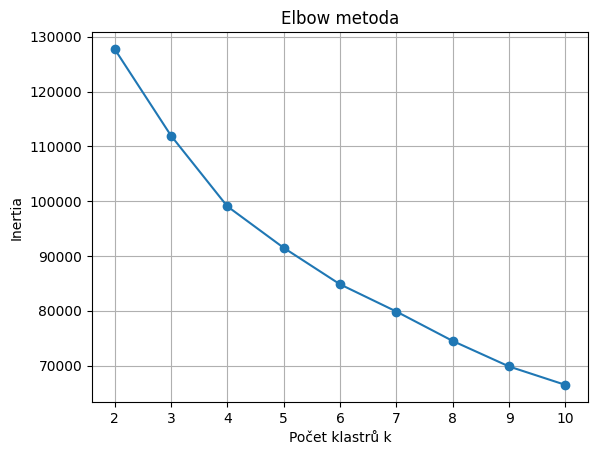

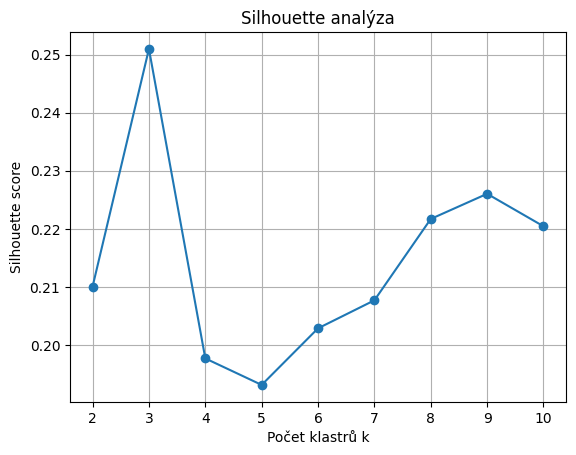


Doporučený počet klastrů podle silhouette: k = 3 (score = 0.2510)

Počty zákazníků v jednotlivých klastrech:


Cluster
0    1275
1    6114
2    1561
Name: count, dtype: int64


Profil klastrů (průměry proměnných):


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
Cluster,,,,,,,,,,,,,,,,,
0,2182.352833,0.981702,4187.017796,2663.995153,1523.493231,449.753140,0.948175,0.664780,0.739630,0.062415,1.507451,55.692549,7642.784314,4075.533648,1227.915879,0.298766,11.916863
1,807.722510,0.834577,496.062522,247.273214,249.110368,338.996760,0.460353,0.129191,0.342052,0.069563,1.236833,8.480046,3267.022176,907.446164,530.068546,0.154115,11.475793
2,4023.788865,0.959193,389.051448,252.333261,136.797412,3917.254973,0.233899,0.111806,0.145661,0.451410,12.551570,5.636131,6729.471201,3053.943771,1765.204181,0.033673,11.353619


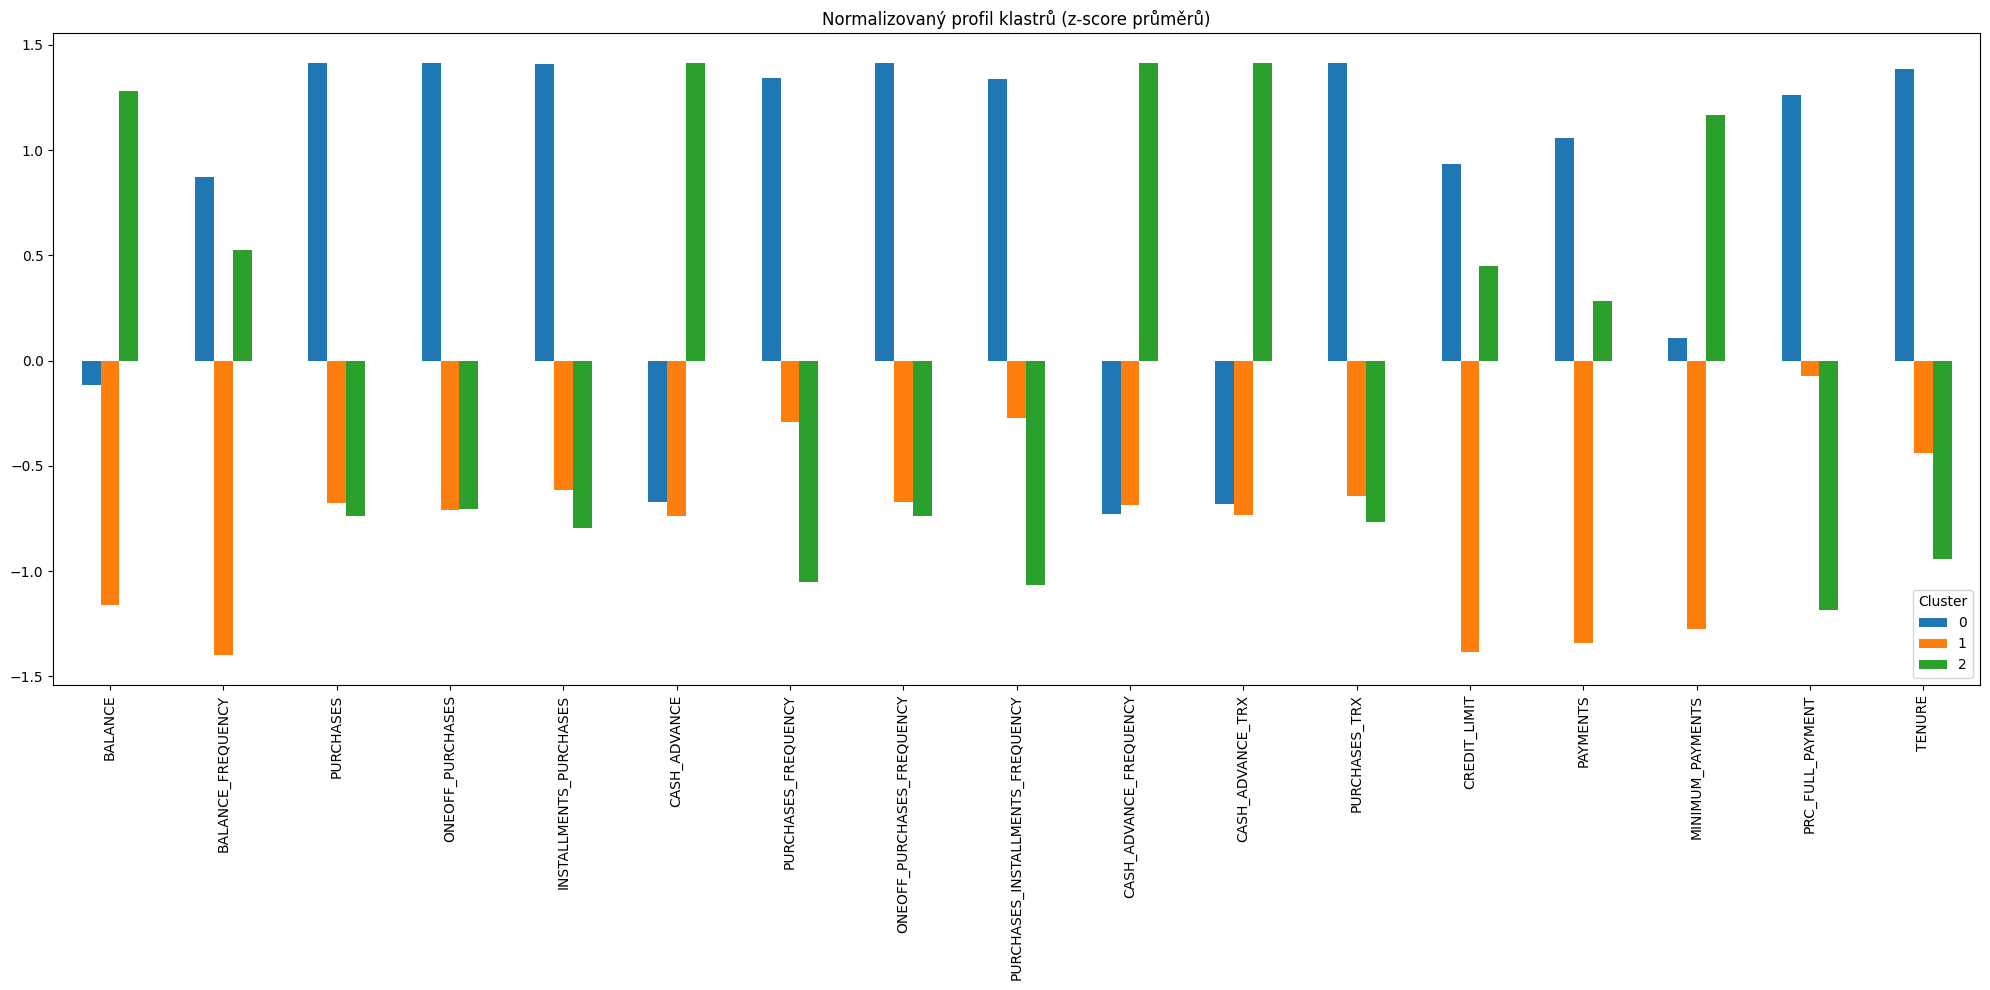

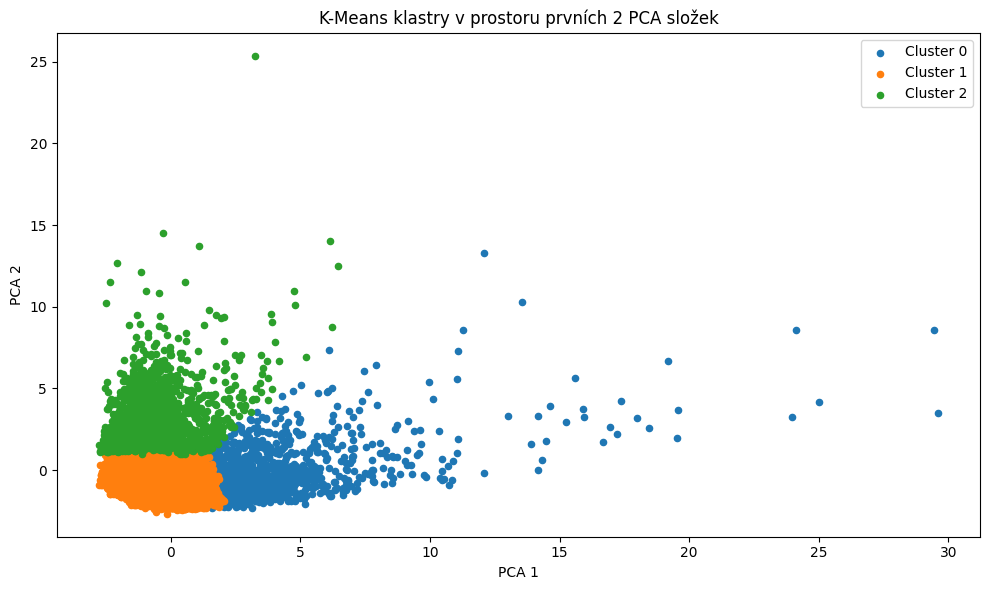


Mediány vybraných klíčových metrik podle klastru:


,BALANCE,PURCHASES,PAYMENTS,MINIMUM_PAYMENTS
Cluster,,,,
0,1193.71,3055.87,2689.04,370.39
1,432.97,299.95,567.73,230.62
2,3508.56,0.00,1654.93,1095.73



Pořadí klastrů v klíčových charakteristikách (od nejvyššího):
- Vysoké nákupy (PURCHASES): [0, 1, 2]

Ukázka dat s klastrem:


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE,Cluster
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0.0,2.0,1000.0,201.802084,139.509787,0.000000,12.0,1
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4.0,0.0,7000.0,4103.032597,1072.340217,0.222222,12.0,2
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0.0,12.0,7500.0,622.066742,627.284787,0.000000,12.0,1
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1.0,1.0,7500.0,0.000000,312.343947,0.000000,12.0,1
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0.0,1.0,1200.0,678.334763,244.791237,0.000000,12.0,1



Hotovo.


In [6]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer

# 2) Načtení dat
url = "https://raw.githubusercontent.com/jplatos/Fundamentals-of-Machine-Learning/refs/heads/main/CCGENERAL.csv"
df = pd.read_csv(url)

print("Tvar dat:", df.shape)
print("\nPrvních 5 řádků:")
display(df.head())

# Zjištění správného názvu ID sloupce
id_col = "CUST_ID" if "CUST_ID" in df.columns else ("CUSTID" if "CUSTID" in df.columns else None)
if id_col is None:
    raise KeyError("Nebyl nalezen identifikátor zákazníka ('CUST_ID' ani 'CUSTID'). Zkontroluj hlavičku datasetu.")

print("\nNázvy sloupců:")
print(df.columns.tolist())

# 3) EDA: základní přehled a popisné statistiky
print("\nInfo:")
df.info()
print("\nPopisné statistiky:")
display(df.describe())

# 3a) Histogramy
_ = df.drop(columns=[id_col]).hist(bins=30, figsize=(18, 15))
plt.suptitle("Histogramy numerických proměnných", y=1.02)
plt.tight_layout()
plt.show()

# 3b) Korelační matice
corr = df.drop(columns=[id_col]).corr(numeric_only=True)
plt.figure(figsize=(14, 10))
im = plt.imshow(corr, aspect='auto')
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.xticks(ticks=np.arange(len(corr.columns)), labels=corr.columns, rotation=90)
plt.yticks(ticks=np.arange(len(corr.columns)), labels=corr.columns)
plt.title("Korelační matice")
plt.tight_layout()
plt.show()

# 4) Chybějící hodnoty
missing = df.isnull().sum().sort_values(ascending=False)
print("\nChybějící hodnoty na sloupec:")
display(missing[missing > 0])

# 4a) Robustní imputace všech numerických sloupců (median)
num_cols = df.drop(columns=[id_col]).select_dtypes(include=[np.number]).columns.tolist()

# nahrazení +/- inf hodnot NaN, aby je chytil imputer
df[num_cols] = df[num_cols].replace([np.inf, -np.inf], np.nan)

imputer = SimpleImputer(strategy="median")
df[num_cols] = imputer.fit_transform(df[num_cols])

# kontrola, že v numerických sloupcích už nejsou NaN
assert not pd.isna(df[num_cols]).any().any(), "Stále zůstaly NaN ve numerických datech."

# 5) Příprava dat pro clustering
X = df.drop(columns=[id_col])   # odstraníme identifikátor
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 6) Volba počtu klastrů: Elbow + Silhouette
inertia = []
sil_scores = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, km.labels_))

# Elbow křivka
plt.figure()
plt.plot(list(K_range), inertia, marker='o')
plt.xlabel("Počet klastrů k")
plt.ylabel("Inertia")
plt.title("Elbow metoda")
plt.grid(True)
plt.show()

# Silhouette skóre
plt.figure()
plt.plot(list(K_range), sil_scores, marker='o')
plt.xlabel("Počet klastrů k")
plt.ylabel("Silhouette score")
plt.title("Silhouette analýza")
plt.grid(True)
plt.show()

best_k = list(K_range)[int(np.argmax(sil_scores))]
print(f"\nDoporučený počet klastrů podle silhouette: k = {best_k} (score = {max(sil_scores):.4f})")

# 7) K-Means s vybraným k
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)
df["Cluster"] = labels

print("\nPočty zákazníků v jednotlivých klastrech:")
display(df["Cluster"].value_counts().sort_index())

# 8) Profilace klastrů
cluster_profile = df.groupby("Cluster").mean(numeric_only=True)
print("\nProfil klastrů (průměry proměnných):")
display(cluster_profile)

# Normalizovaný profil pro porovnání napříč proměnnými (z-score průměrů)
profile_norm = (cluster_profile - cluster_profile.mean()) / cluster_profile.std(ddof=0)

# Sloupcový graf profilů
ax = profile_norm.T.plot(kind="bar", figsize=(20, 10))
plt.title("Normalizovaný profil klastrů (z-score průměrů)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# 9) PCA vizualizace v 2D
pca = PCA(n_components=2, random_state=42)
components = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))
for c in sorted(np.unique(labels)):
    mask = labels == c
    plt.scatter(components[mask, 0], components[mask, 1], label=f"Cluster {c}", s=20)
plt.title("K-Means klastry v prostoru prvních 2 PCA složek")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.legend()
plt.tight_layout()
plt.show()

# 10) Stručná interpretace podle typických vzorců
key_cols = [
    "BALANCE","PURCHASES","ONEOFFPURCHASES","INSTALLMENTSPURCHASES",
    "CASHADVANCE","PURCHASESTRX","CASHADVANCETRX","CREDITLIMIT",
    "PAYMENTS","MINIMUM_PAYMENTS","PRCFULLPAYMENT"
]
available_cols = [c for c in key_cols if c in df.columns]

summary = df.groupby("Cluster")[available_cols].median().round(2)
print("\nMediány vybraných klíčových metrik podle klastru:")
display(summary)

def rank_desc(col):
    return summary[col].sort_values(ascending=False).index.tolist()

signals = {
    "Vysoké nákupy (PURCHASES)": rank_desc("PURCHASES") if "PURCHASES" in summary else [],
    "One-off nákupy (ONEOFFPURCHASES)": rank_desc("ONEOFFPURCHASES") if "ONEOFFPURCHASES" in summary else [],
    "Nákupy na splátky (INSTALLMENTSPURCHASES)": rank_desc("INSTALLMENTSPURCHASES") if "INSTALLMENTSPURCHASES" in summary else [],
    "Cash advance (CASHADVANCE)": rank_desc("CASHADVANCE") if "CASHADVANCE" in summary else [],
    "Počet nákupních transakcí (PURCHASESTRX)": rank_desc("PURCHASESTRX") if "PURCHASESTRX" in summary else [],
    "Počet cash advance transakcí (CASHADVANCETRX)": rank_desc("CASHADVANCETRX") if "CASHADVANCETRX" in summary else [],
    "Limit karty (CREDITLIMIT)": rank_desc("CREDITLIMIT") if "CREDITLIMIT" in summary else [],
    "Podíl plných úhrad (PRCFULLPAYMENT)": rank_desc("PRCFULLPAYMENT") if "PRCFULLPAYMENT" in summary else [],
}

print("\nPořadí klastrů v klíčových charakteristikách (od nejvyššího):")
for k, v in signals.items():
    if len(v) > 0:
        print(f"- {k}: {v}")

print("\nUkázka dat s klastrem:")
display(df.head())

print("\nHotovo.")